In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter


**Plan**:
1️⃣ Charger les bibliothèques
2️⃣ Charger le dataset
3️⃣ Explorer la structure des dossiers
4️⃣Compter les classes 
5️⃣ Visualiser la distribution
6️⃣ Afficher des images
7️⃣ Vérifier la taille des images
8️⃣Vérifier s’il y a des images corrompues
 Conclusion 

**CHARGER LE DATASET**

Présentation du dataset:
Le dataset utilisé dans ce projet est PlantVillage, un ensemble d’images de feuilles de plantes annotées selon le type de plante et la maladie associée. Il est largement utilisé dans les projets de vision par ordinateur dédiés à l’agriculture intelligente.

In [2]:
DATASET_PATH = "/kaggle/input/plantvillage-dataset/color"

**EXPLORER LA STRUCTURE DU DATASET**

Une phase de data exploration a été réalisée afin de mieux comprendre la structure et le contenu du dataset. Cette étape permet d’analyser le nombre de classes, la répartition des images par classe, ainsi que les caractéristiques visuelles des images.


In [3]:
classes = os.listdir(DATASET_PATH)
print("Nombre de classes :", len(classes))
print(classes)

Nombre de classes : 38
['Tomato___Late_blight', 'Tomato___healthy', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Potato___healthy', 'Corn_(maize)___Northern_Leaf_Blight', 'Tomato___Early_blight', 'Tomato___Septoria_leaf_spot', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Strawberry___Leaf_scorch', 'Peach___healthy', 'Apple___Apple_scab', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Bacterial_spot', 'Apple___Black_rot', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Peach___Bacterial_spot', 'Apple___Cedar_apple_rust', 'Tomato___Target_Spot', 'Pepper,_bell___healthy', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Potato___Late_blight', 'Tomato___Tomato_mosaic_virus', 'Strawberry___healthy', 'Apple___healthy', 'Grape___Black_rot', 'Potato___Early_blight', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Common_rust_', 'Grape___Esca_(Black_Measles)', 'Raspberry___healthy', 'Tomato_

In [4]:
plant_classes = sorted(set(c.split("___")[0] for c in classes))
plant_classes

['Apple',
 'Blueberry',
 'Cherry_(including_sour)',
 'Corn_(maize)',
 'Grape',
 'Orange',
 'Peach',
 'Pepper,_bell',
 'Potato',
 'Raspberry',
 'Soybean',
 'Squash',
 'Strawberry',
 'Tomato']

**COMPTER LES IMAGES PAR CLASSE**

In [5]:
image_count = {}

for class_name in classes:
    class_path = os.path.join(DATASET_PATH, class_name)
    image_count[class_name] = len(os.listdir(class_path))

image_count

{'Tomato___Late_blight': 1909,
 'Tomato___healthy': 1591,
 'Grape___healthy': 423,
 'Orange___Haunglongbing_(Citrus_greening)': 5507,
 'Soybean___healthy': 5090,
 'Squash___Powdery_mildew': 1835,
 'Potato___healthy': 152,
 'Corn_(maize)___Northern_Leaf_Blight': 985,
 'Tomato___Early_blight': 1000,
 'Tomato___Septoria_leaf_spot': 1771,
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': 513,
 'Strawberry___Leaf_scorch': 1109,
 'Peach___healthy': 360,
 'Apple___Apple_scab': 630,
 'Tomato___Tomato_Yellow_Leaf_Curl_Virus': 5357,
 'Tomato___Bacterial_spot': 2127,
 'Apple___Black_rot': 621,
 'Blueberry___healthy': 1502,
 'Cherry_(including_sour)___Powdery_mildew': 1052,
 'Peach___Bacterial_spot': 2297,
 'Apple___Cedar_apple_rust': 275,
 'Tomato___Target_Spot': 1404,
 'Pepper,_bell___healthy': 1478,
 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)': 1076,
 'Potato___Late_blight': 1000,
 'Tomato___Tomato_mosaic_virus': 373,
 'Strawberry___healthy': 456,
 'Apple___healthy': 1645,
 'Grape___Black

**COMPTER LES IMAGES PAR PLANTE**

In [6]:
plant_image_count = {}

for class_name in classes:
    plant_name = class_name.split("___")[0]
    class_path = os.path.join(DATASET_PATH, class_name)
    nb_images = len(os.listdir(class_path))
    
    if plant_name in plant_image_count:
        plant_image_count[plant_name] += nb_images
    else:
        plant_image_count[plant_name] = nb_images

plant_image_count


{'Tomato': 18160,
 'Grape': 4062,
 'Orange': 5507,
 'Soybean': 5090,
 'Squash': 1835,
 'Potato': 2152,
 'Corn_(maize)': 3852,
 'Strawberry': 1565,
 'Peach': 2657,
 'Apple': 3171,
 'Blueberry': 1502,
 'Cherry_(including_sour)': 1906,
 'Pepper,_bell': 2475,
 'Raspberry': 371}

**CONVERTIR EN DATAFRAME**

In [7]:
df_plants = pd.DataFrame(
    plant_image_count.items(),
    columns=["Plante", "Nombre total d'images"]
)

df_plants

,Plante,Nombre total d'images
0,Tomato,18160
1,Grape,4062
2,Orange,5507
3,Soybean,5090
4,Squash,1835
5,Potato,2152
6,Corn_(maize),3852
7,Strawberry,1565
8,Peach,2657
9,Apple,3171


**VISUALISER LA DISTRIBUTION PAR PLANTE**

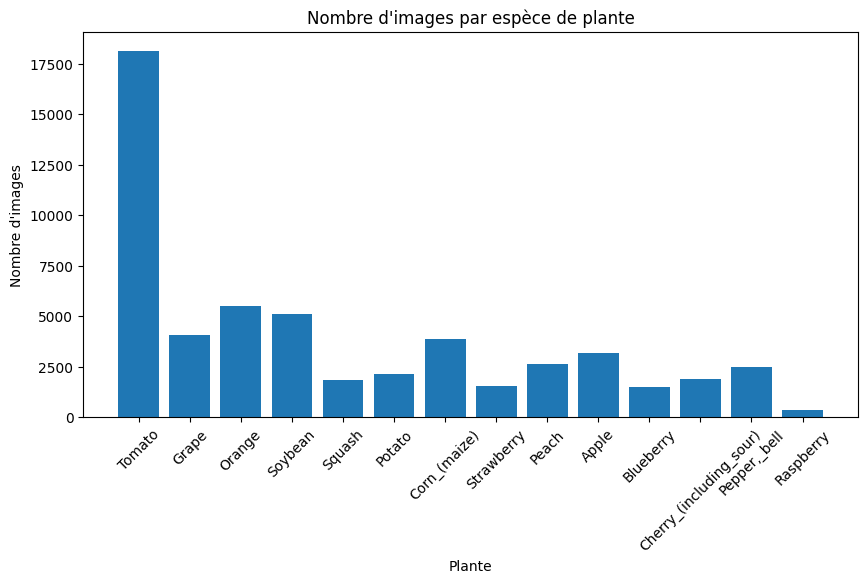

In [8]:
plt.figure(figsize=(10,5))
plt.bar(df_plants["Plante"], df_plants["Nombre total d'images"])
plt.xticks(rotation=45)
plt.title("Nombre d'images par espèce de plante")
plt.xlabel("Plante")
plt.ylabel("Nombre d'images")
plt.show()

**la classe "Tomato" est surreprésentée par rapport aux autres plantes, avec un nombre d’images nettement supérieur.Le modèle pourrait être davantage influencé par les caractéristiques des feuilles de tomate, ce qui peut entraîner un biais lors de l’apprentissage et affecter les performances de classification pour les espèces moins représentées.**

**NOMBRE DE MALADIES PAR PLANTE**

In [9]:
plant_disease_count = {}

for class_name in classes:
    plant_name = class_name.split("___")[0]
    
    if plant_name in plant_disease_count:
        plant_disease_count[plant_name] += 1
    else:
        plant_disease_count[plant_name] = 1

df_diseases = pd.DataFrame(
    plant_disease_count.items(),
    columns=["Plante", "Nombre de classes (maladies)"]
)

df_diseases

,Plante,Nombre de classes (maladies)
0,Tomato,10
1,Grape,4
2,Orange,1
3,Soybean,1
4,Squash,1
5,Potato,3
6,Corn_(maize),4
7,Strawberry,2
8,Peach,2
9,Apple,4


**AFFICHER DES IMAGES DU DATASET**

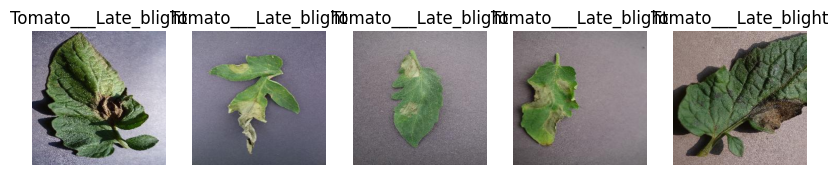

In [10]:
sample_class = classes[0]
sample_path = os.path.join(DATASET_PATH, sample_class)

images = os.listdir(sample_path)[:5]

plt.figure(figsize=(10,4))
for i, img_name in enumerate(images):
    img = Image.open(os.path.join(sample_path, img_name))
    plt.subplot(1,5,i+1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(sample_class)
plt.show()


**VÉRIFIER LA TAILLE DES IMAGES**

In [11]:
img = Image.open(os.path.join(sample_path, images[0]))
print("Taille de l'image :", img.size)


Taille de l'image : (256, 256)


Vérifier s’il y a des images corrompues

In [12]:
broken_images = 0

for class_name in classes:
    class_path = os.path.join(DATASET_PATH, class_name)
    for img_name in os.listdir(class_path):
        try:
            img = Image.open(os.path.join(class_path, img_name))
            img.verify()
        except:
            broken_images += 1

broken_images


0

**Conclusion ** :
La data exploration a permis de mieux comprendre le dataset PlantVillage, d’identifier les différentes classes, d’analyser la distribution des données et d’observer les caractéristiques des images. Cette étape est essentielle pour préparer efficacement les données avant l’entraînement des modèles.
